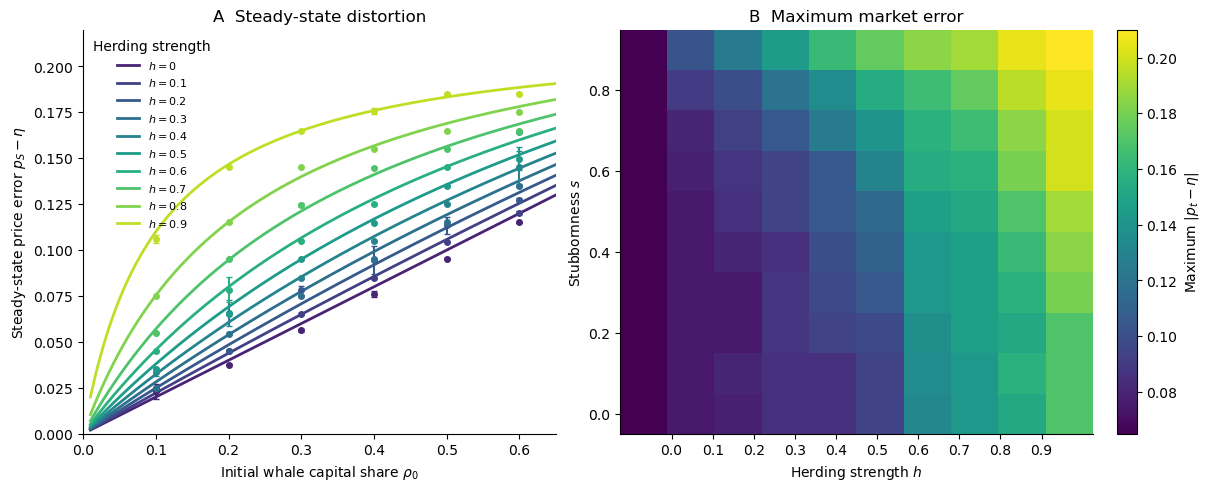

       count      mean       std    min      25%     50%   75%   max
panel                                                               
A       90.0  0.952556  0.091536  0.485  0.97125  0.9850  0.99  0.99
B      100.0  0.978000  0.046575  0.605  0.98500  0.9875  0.99  0.99


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bettor import bettor, run_market_lob

# ============================================================
# 1. Experimental settings
# ============================================================

ETA = 0.5
W = 0.7
DELTA = W - ETA

N = 100
T = 100
TAIL = 50
N_REPS = 2  # Increase to 100-500 for final figures

RHO_VALUES = np.arange(0.1, 0.91, 0.1)
H_VALUES = np.linspace(0, 0.9, 10)
S_VALUES = np.linspace(0, 0.9, 10)

S_FIXED = 0.1
RHO_FIXED = 0.3

# ============================================================
# 2. Theory
# ============================================================

def theoretical_error(rho, h, s, delta=DELTA):
    numerator = (1-h)*(1-s) + h
    denominator = (1-h)*(1-s) + h*rho
    return rho * delta * numerator / denominator

# ============================================================
# 3. Simulation wrapper
# ============================================================

def simulate(rho, h, s, seed, B=100):
    np.random.seed(seed)
    rng = np.random.default_rng(seed)

    agents = [
        bettor(
            budget=B,
            market_valuation=ETA,
            n_contracts=0,
            risk_av=1.0,
            stubbornness=s,
            expertise=1.0,  # No signal noise
            market_imitation=h,
            bias=0
        )
        for _ in range(N)
    ]

    record = run_market_lob(
        n_bettors=N,
        t_election=T,
        initial_price=ETA,
        outcome_uncertainty=0,
        bettors=agents,
        gen_el=np.full(T, ETA),
        whale_share=rho,
        whale_start=0,
        whale_valuation=W,
        tick=0.01,
        max_markup=0.05,
        rng=rng
    )

    # End-of-period reference price, including quote fallbacks
    price = np.asarray(
        record["reference_price"][1:],
        dtype=float
    )

    # True two-sided midquote for diagnostic checks
    midquote = np.asarray(
        record["midquote"],
        dtype=float
    )

    return {
        "steady_error": np.mean(price[-TAIL:] - ETA),
        "max_error": np.max(np.abs(price - ETA)),
        "midquote_coverage": np.mean(np.isfinite(midquote))
    }

# ============================================================
# 4. Run parameter sweep
# ============================================================

rows = []

def run_condition(rho, h, s, reps=N_REPS, B=100):
    results = [
        simulate(rho, h, s, seed=10000 + rep, B=B)
        for rep in range(reps)
    ]
    return {
        "steady_error": np.mean(
            [r["steady_error"] for r in results]
        ),
        "steady_se": np.std(
            [r["steady_error"] for r in results], ddof=1
        ) / np.sqrt(reps),
        "max_error": np.mean(
            [r["max_error"] for r in results]
        ),
        "midquote_coverage": np.mean(
            [r["midquote_coverage"] for r in results]
        )
    }

# Panel A
for h in H_VALUES:
    for rho in RHO_VALUES:
        result = run_condition(rho, h, S_FIXED)
        rows.append({
            "panel": "A",
            "rho": rho,
            "h": h,
            "s": S_FIXED,
            **result
        })

# Panel B
for s in S_VALUES:
    for h in H_VALUES:
        result = run_condition(RHO_FIXED, h, s)
        rows.append({
            "panel": "B",
            "rho": RHO_FIXED,
            "h": h,
            "s": s,
            **result
        })

df = pd.DataFrame(rows)
df.to_csv("whale_herding_results.csv", index=False)

# ============================================================
# 5. Plot both panels
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.8),
    constrained_layout=True
)

colors = plt.cm.viridis(
    np.linspace(0.1, 0.9, len(H_VALUES))
)

# ------------------------------------------------------------
# Panel A: Theory and simulation
# ------------------------------------------------------------

ax = axes[0]
rho_dense = np.linspace(0.01, 0.65, 300)

for h, color in zip(H_VALUES, colors):

    ax.plot(
        rho_dense,
        theoretical_error(
            rho_dense, h, S_FIXED
        ),
        color=color,
        lw=2,
        label=fr"$h={h:g}$"
    )

    subset = df[
        (df.panel == "A") &
        (np.isclose(df.h, h))
    ].sort_values("rho")

    ax.errorbar(
        subset.rho,
        subset.steady_error,
        yerr=1.96 * subset.steady_se,
        fmt="o",
        color=color,
        capsize=2,
        markersize=4,
        linestyle="none"
    )

ax.set(
    title="A  Steady-state distortion",
    xlabel=r"Initial whale capital share $\rho_0$",
    ylabel=r"Steady-state price error $p_S-\eta$",
    xlim=(0, 0.65),
    ylim=(0, 0.22)
)

ax.legend(
    title="Herding strength",
    frameon=False,
    fontsize=8
)

# ------------------------------------------------------------
# Panel B: Maximum error by h and s
# ------------------------------------------------------------

ax = axes[1]

subset = df[df.panel == "B"]

heatmap = subset.pivot(
    index="s",
    columns="h",
    values="max_error"
)

im = ax.imshow(
    heatmap.values,
    origin="lower",
    aspect="auto",
    extent=[
        min(H_VALUES)-0.125,
        max(H_VALUES)+0.125,
        min(S_VALUES)-0.05,
        max(S_VALUES)+0.05
    ],
    cmap="viridis"
)

ax.set(
    title="B  Maximum market error",
    xlabel=r"Herding strength $h$",
    ylabel=r"Stubbornness $s$"
)

ax.set_xticks(H_VALUES)

fig.colorbar(
    im, ax=ax,
    label=r"Maximum $|p_t-\eta|$"
)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(
    "figure4_whale_herding.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "figure4_whale_herding.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    df.groupby("panel")[
        "midquote_coverage"
    ].describe()
)


In [24]:

# ============================================================
# DIAGNOSTICS: theory versus simulated CLOB
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bettor import bettor, run_market_lob

# Use your existing ETA, W, DELTA, N, S_FIXED,
# and theoretical_error() definitions.

DIAG_T = 300
DIAG_TAIL = 75
DIAG_REPS = 30

DIAG_RHOS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
DIAG_H = [0.0, 0.5, 0.9]

# ------------------------------------------------------------
# 1. Run a simulation and retain portfolios and trajectories
# ------------------------------------------------------------

def diagnostic_simulation(rho, h, s, seed, T=DIAG_T):
    np.random.seed(seed)
    rng = np.random.default_rng(seed)

    agents = [
        bettor(
            budget=100,
            market_valuation=ETA,
            n_contracts=0,
            risk_av=1.0,
            stubbornness=s,
            expertise=1.0,
            market_imitation=h,
            bias=0
        )
        for _ in range(N)
    ]

    record = run_market_lob(
        n_bettors=N,
        t_election=T,
        initial_price=ETA,
        outcome_uncertainty=0,
        bettors=agents,
        gen_el=np.full(T, ETA),
        whale_share=rho,
        whale_start=0,
        whale_valuation=W,
        tick=0.01,
        max_markup=0.05,
        rng=rng
    )

    price = np.asarray(
        record["reference_price"][1:], dtype=float
    )

    midquote = np.asarray(
        record["midquote"], dtype=float
    )

    assert len(price) == T
    assert len(midquote) == T
    assert len(agents) == N + 1

    # The whale is appended by run_market_lob.
    whale = agents[-1]
    assert whale.whale

    # IMPORTANT:
    # This requires changing the whale's risk_av
    # from 0.5 to 1.0 inside run_market_lob.
    assert np.isclose(whale.risk_av, 1.0), (
        "Set whale risk_av=1.0 in bettor.py first."
    )

    # Final mark-to-market wealth at the final price
    final_price = price[-1]

    wealth = np.array([
        a.budget + final_price * a.n_contracts
        for a in agents
    ])

    rho_final = wealth[-1] / wealth.sum()

    # Also calculate the wealth-weighted mean
    # valuation of ordinary traders.
    ordinary_wealth = wealth[:-1]
    ordinary_valuations = np.array([
        a.market_valuation for a in agents[:-1]
    ])

    ordinary_mean = np.average(
        ordinary_valuations,
        weights=ordinary_wealth
    )

    # Empirical steady-state estimate
    delta_sim = np.mean(price[-DIAG_TAIL:] - ETA)

    # Two alternative theoretical predictions
    delta_theory_initial = theoretical_error(
        rho, h, s
    )

    delta_theory_final = theoretical_error(
        rho_final, h, s
    )

    # Direct wealth-weighted valuation benchmark
    weighted_price = np.average(
        [a.market_valuation for a in agents],
        weights=wealth
    )

    return {
        "rho0": rho,
        "rho_final": rho_final,
        "h": h,
        "s": s,
        "seed": seed,
        "delta_sim": delta_sim,
        "theory_initial": delta_theory_initial,
        "theory_final": delta_theory_final,
        "residual_initial": (
            delta_sim - delta_theory_initial
        ),
        "residual_final": (
            delta_sim - delta_theory_final
        ),
        "ordinary_mean": ordinary_mean,
        "ordinary_bias": ordinary_mean - ETA,
        "weighted_price_gap": (
            final_price - weighted_price
        ),
        "midquote_coverage": np.mean(
            np.isfinite(midquote)
        ),
        "reference_tail": np.mean(
            price[-DIAG_TAIL:]
        ),
        "midquote_tail": (
            np.nanmean(midquote[-DIAG_TAIL:])
            if np.isfinite(
                midquote[-DIAG_TAIL:]
            ).any()
            else np.nan
        ),
        "price": price,
        "midquote": midquote
    }


# ------------------------------------------------------------
# 2. Run targeted parameter combinations
# ------------------------------------------------------------

results = []

for h in DIAG_H:
    for rho in DIAG_RHOS:
        for rep in range(DIAG_REPS):

            result = diagnostic_simulation(
                rho=rho,
                h=h,
                s=S_FIXED,
                seed=10000 + rep
            )

            results.append(result)

diagnostics = pd.DataFrame(results)

print("Completed", len(diagnostics), "simulations")


# ------------------------------------------------------------
# 3. Summary table
# ------------------------------------------------------------

summary = (
    diagnostics
    .groupby(["h", "rho0"])
    .agg(
        simulated=("delta_sim", "mean"),
        theory_initial=("theory_initial", "mean"),
        theory_final=("theory_final", "mean"),
        rho_final=("rho_final", "mean"),
        residual_initial=("residual_initial", "mean"),
        residual_final=("residual_final", "mean"),
        ordinary_bias=("ordinary_bias", "mean"),
        clearing_gap=("weighted_price_gap", "mean"),
        midquote_coverage=("midquote_coverage", "mean")
    )
    .reset_index()
)

display(summary.round(4))

summary.to_csv(
    "whale_diagnostic_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 4. Diagnostic plots
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    # constrained_layout=True
)

colors = plt.cm.viridis(
    np.linspace(0.15, 0.85, len(DIAG_H))
)

# ============================================================
# A. No-herding baseline
# ============================================================

ax = axes[0, 0]

sub = summary[np.isclose(summary.h, 0)]

ax.plot(
    sub.rho0,
    sub.theory_initial,
    "k--",
    label=r"Theory using $\rho_0$"
)

ax.plot(
    sub.rho0,
    sub.theory_final,
    "s-",
    label=r"Theory using $\rho_S$"
)

ax.plot(
    sub.rho0,
    sub.simulated,
    "o-",
    label="Simulation"
)

ax.set(
    title="A  No-herding baseline",
    xlabel=r"Initial whale share $\rho_0$",
    ylabel=r"Steady-state error $\delta_S$"
)

ax.legend(frameon=False)


# ============================================================
# B. Initial versus final wealth share
# ============================================================

ax = axes[0, 1]

for h, color in zip(DIAG_H, colors):

    sub = summary[np.isclose(summary.h, h)]

    ax.plot(
        sub.rho0,
        sub.rho_final,
        "o-",
        color=color,
        label=fr"$h={h:g}$"
    )

ax.plot(
    [0, 0.65],
    [0, 0.65],
    "k--",
    alpha=0.6,
    label=r"$\rho_S=\rho_0$"
)

ax.set(
    title="B  Does the whale's wealth share change?",
    xlabel=r"Initial wealth share $\rho_0$",
    ylabel=r"Final wealth share $\rho_S$"
)

ax.legend(frameon=False)


# ============================================================
# C. Residuals after correcting wealth share
# ============================================================

ax = axes[1, 0]

for h, color in zip(DIAG_H, colors):

    sub = summary[np.isclose(summary.h, h)]

    ax.plot(
        sub.rho0,
        sub.residual_final,
        "o-",
        color=color,
        label=fr"$h={h:g}$"
    )

ax.axhline(0, color="black", ls="--", lw=1)

ax.set(
    title="C  Simulation minus corrected theory",
    xlabel=r"Initial whale share $\rho_0$",
    ylabel=r"$\delta_S^{sim}-\delta_S^{theory}(\rho_S)$"
)

ax.legend(frameon=False)


# ============================================================
# D. Example price trajectories
# ============================================================

ax = axes[1, 1]

rho_example = 0.3

for h, color in zip(DIAG_H, colors):

    sub = diagnostics[
        np.isclose(diagnostics.h, h)
        & np.isclose(diagnostics.rho0, rho_example)
    ]

    paths = np.stack(sub.price.to_numpy())

    mean_path = np.mean(paths, axis=0)

    ax.plot(
        np.arange(len(mean_path)),
        mean_path - ETA,
        color=color,
        label=fr"$h={h:g}$"
    )

    theory = theoretical_error(
        rho_example, h, S_FIXED
    )

    ax.axhline(
        theory,
        color=color,
        ls="--",
        alpha=0.65
    )

ax.set(
    title=r"D  Price adjustment, $\rho_0=0.3$",
    xlabel="Period",
    ylabel=r"Price error $p_t-\eta$"
)

ax.legend(
    title="Solid: simulation\nDashed: initial-share theory",
    frameon=False
)

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig(
    "whale_diagnostics.pdf",
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 5. Additional checks
# ------------------------------------------------------------

print("\nMean absolute residuals:")
print(
    diagnostics[
        ["residual_initial", "residual_final"]
    ].abs().mean()
)

print("\nAverage ordinary trader valuation bias:")
print(
    diagnostics.groupby("h")[
        "ordinary_bias"
    ].mean()
)

print("\nReference price versus true midquote:")
print(
    diagnostics.groupby("h")[
        ["reference_tail",
         "midquote_tail",
         "midquote_coverage"]
    ].mean()
)

print("\nAverage gap from weighted-valuation price:")
print(
    diagnostics.groupby("h")[
        "weighted_price_gap"
    ].mean()
)


KeyboardInterrupt: 

In [3]:
# remaking plot
# load in data from whale_herding_results.csv 

df_parallel = pd.read_csv("whale_herding_results.csv")

In [4]:
df_parallel.head()

,panel,rho,h,s,steady_error,steady_se,max_error,midquote_coverage
0,A,0.1,0.0,0.1,0.018970,0.000223,0.04825,0.8178
1,A,0.2,0.0,0.1,0.036441,0.000068,0.08540,0.9848
2,A,0.3,0.0,0.1,0.055737,0.000069,0.12375,0.9861
3,A,0.4,0.0,0.1,0.075198,0.000021,0.15020,0.9825
4,A,0.5,0.0,0.1,0.095190,0.000017,0.16200,0.9768


In [58]:

def plot_figure(df, show=False):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))#, constrained_layout=True)
    # add some space between the two plots and allow for tight layout
    fig.subplots_adjust(wspace=0.3)

    colors = plt.cm.cool(np.linspace(0.1, 0.9, len(H_VALUES)))[::-1]
    ax = axes[0]
    rho_dense = np.linspace(0.01, 0.65, 300)
    for h, color in zip(H_VALUES, colors):
        ax.plot(rho_dense, theoretical_error(rho_dense, h, S_FIXED),
                color=color, lw=2, label=fr'$h={h:g}$', alpha=0.6)
        subset = df[(df.panel == 'A') & (np.isclose(df.h, h))].sort_values('rho')
        ax.errorbar(subset.rho, subset.steady_error,
                    yerr=1.96 * subset.steady_se, fmt='o', color=color,
                    capsize=2, markersize=4, linestyle='none')
    ax.set(title='A  Steady-state distortion',
           xlabel=r'Initial whale capital share ($\rho_0$)',
           ylabel=r'Steady-state price error ($p_S-\eta$)',
           xlim=(0, 0.65), ylim=(0, 0.22))
    # move legend below the plot
    ax.legend(title='Herding strength', frameon=True, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=5)
    ax = axes[1]
    subset = df[df.panel == 'B']
    heatmap = subset.pivot(index='s', columns='h', values='max_error')
    im = ax.imshow(heatmap.values, origin='lower', aspect='auto',
                   extent=[min(H_VALUES)-0.125, max(H_VALUES)+0.125,
                           min(S_VALUES)-0.05, max(S_VALUES)+0.05], cmap='viridis')
    ax.set(title='B  Maximum market error', xlabel=r'Herding strength ($h$)',
           ylabel=r'Stubbornness ($s$)')
    ax.set_xticks(H_VALUES)
    fig.colorbar(im, ax=ax, label=r'Maximum ($|p_t-\eta|$)')
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.savefig('figure4_whale_herding.pdf', bbox_inches='tight')
    fig.savefig('figure4_whale_herding.png', dpi=300, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)

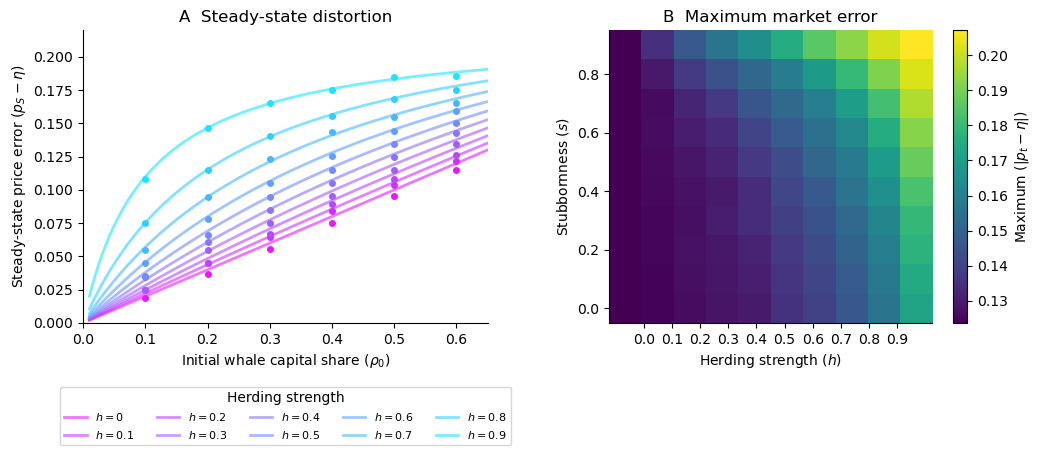

In [59]:
plot_figure(df_parallel, show=True)